In [ ]:
!pip install -q xgboost lightgbm optuna shap lime scikit-learn pandas numpy matplotlib seaborn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 14.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 22.6 MB/s eta 0:00:00


In [ ]:
# @title
# ============================================================
# Librerías
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score, roc_curve, classification_report, confusion_matrix
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import LocalOutlierFactor
from sklearn.decomposition import PCA
from sklearn.inspection import PartialDependenceDisplay
from sklearn.linear_model import LogisticRegression

from xgboost import XGBClassifier, plot_importance
from lightgbm import LGBMClassifier

import optuna
from optuna.samplers import TPESampler

import shap
from lime.lime_tabular import LimeTabularExplainer

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

In [ ]:
df = pd.read_csv("creditoefectivo_GBM.csv")

In [ ]:
# @title
# ============================================================
# Análisis del target
# ============================================================

target = "default"
features = [c for c in df.columns if c != target]

target_summary = df[target].value_counts().to_frame("conteo")
target_summary["porcentaje"] = target_summary["conteo"] / len(df)
target_summary

,conteo,porcentaje
default,,
0,11603,0.9669
1,397,0.0331


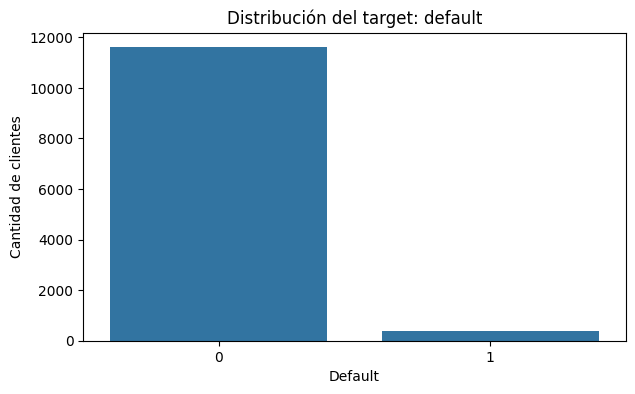

Tasa de default: 3.31%
No default / Default ratio: 29.23x


In [ ]:
# @title
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x=target)
plt.title("Distribución del target: default")
plt.xlabel("Default")
plt.ylabel("Cantidad de clientes")
plt.show()

default_rate = df[target].mean()
print(f"Tasa de default: {default_rate:.2%}")
print(f"No default / Default ratio: {(1-default_rate)/default_rate:.2f}x")

In [ ]:
# @title
# ============================================================
# 4. Train/test split
# ============================================================

X = df[features].copy()
y = df[target].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

print(X_train.shape, X_test.shape)
print("Default train:", y_train.mean())
print("Default test :", y_test.mean())

(9000, 20) (3000, 20)
Default train: 0.03311111111111111
Default test : 0.033


In [ ]:
# ============================================================
# Outlier treatment: percentil 1 y percentil 99
# ============================================================

def winsorize_train_test(X_train, X_test, lower_q=0.01, upper_q=0.99):
    X_train_w = X_train.copy()
    X_test_w = X_test.copy()
    bounds = {}

    for col in X_train.columns:
        lo = X_train[col].quantile(lower_q)
        hi = X_train[col].quantile(upper_q)
        bounds[col] = (lo, hi)
        X_train_w[col] = X_train[col].clip(lo, hi)
        X_test_w[col] = X_test[col].clip(lo, hi)

    return X_train_w, X_test_w, bounds

X_train_w, X_test_w, winsor_bounds = winsorize_train_test(X_train, X_test)

pd.DataFrame(winsor_bounds, index=["p01", "p99"]).T.head(10)

,p01,p99
edad,18.0000,63.8038
ingreso_mensual,"1,020.7654","17,172.3395"
ingreso_anual_estimado,"11,549.5959","156,058.8402"
deuda_total,185.9886,"12,644.8965"
ratio_deuda_ingreso,0.0816,1.6961
endeudamiento_buro,0.0060,1.7484
utilizacion_tc,0.0662,0.8634
mora_ult_12m,0.0000,2.0000
consultas_buro_6m,0.0000,5.0000
antiguedad_laboral_meses,7.8651,169.0228


## Análisis LOF: Local Outlier Factor

LOF identifica observaciones con densidad local menor que la de sus vecinos, la densidad va a ser la inversa de la distancia al vencino 35. Es útil para revisar perfiles atípicos multivariados.
El LOF va a ser un ratio entre la densidad promedio de los vecinos y la densidad del punto de interés.

Aquí no se eliminan automáticamente observaciones. Se usa como diagnóstico, porque en riesgo crediticio los outliers pueden representar segmentos reales de alto riesgo.

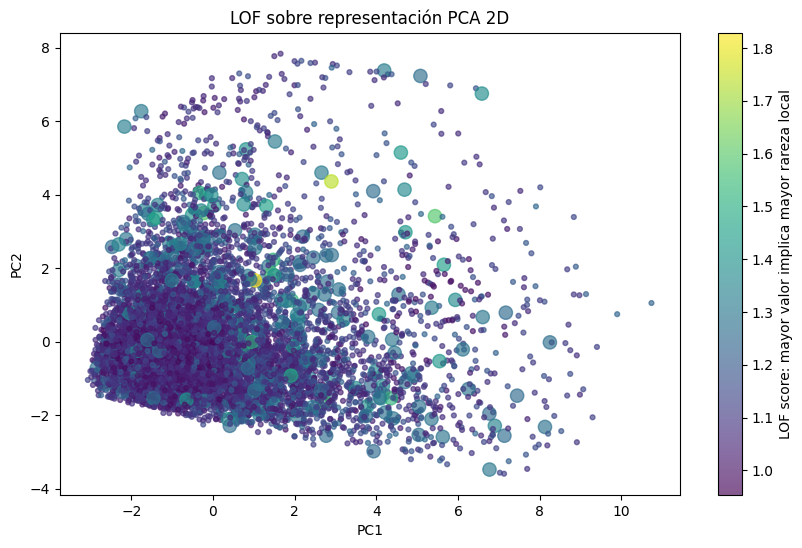

Porcentaje marcado como outlier LOF (ya lo definimos en la contaminación): 0.03
Default rate outliers LOF: 0.0815
Default rate no outliers: 0.0316


In [ ]:
# ============================================================
# LOF con visualización PCA 2D
# ============================================================

lof_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_train_lof_scaled = lof_pipe.fit_transform(X_train_w)

lof = LocalOutlierFactor(n_neighbors=35, contamination=0.03) #vamos a asumir que el 3% de registros son anómalos
lof_label = lof.fit_predict(X_train_lof_scaled)
lof_score = -lof.negative_outlier_factor_

pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca_2d.fit_transform(X_train_lof_scaled)

lof_df = pd.DataFrame({
    "PC1": coords[:, 0],
    "PC2": coords[:, 1],
    "LOF_score": lof_score,
    "is_outlier_lof": (lof_label == -1).astype(int),
    "default": y_train.values
})

plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    lof_df["PC1"], lof_df["PC2"],
    c=lof_df["LOF_score"],
    s=12 + 80 * lof_df["is_outlier_lof"],
    alpha=0.65
)
plt.colorbar(scatter, label="LOF score: mayor valor implica mayor rareza local")
plt.title("LOF sobre representación PCA 2D")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

print("Porcentaje marcado como outlier LOF (ya lo definimos en la contaminación):", lof_df["is_outlier_lof"].mean().round(4))
print("Default rate outliers LOF:", lof_df.loc[lof_df.is_outlier_lof == 1, "default"].mean().round(4))
print("Default rate no outliers:", lof_df.loc[lof_df.is_outlier_lof == 0, "default"].mean().round(4))

## Selección inicial por matriz de reglas: missings vs. Gini univariado

Se calcula para cada variable:

- Porcentaje de missings.
- AUC univariado.
- Gini univariado absoluto: `abs(2*AUC - 1)`.

Luego se usa una matriz de decisión:

| Missing rate | Gini bajo < 3% | Gini medio 3%-8% | Gini alto >= 8% |
|---|---:|---:|---:|
| <= 10% | Revisar | Mantener | Mantener |
| 10%-30% | Eliminar | Revisar | Mantener |
| > 30% | Eliminar | Eliminar | Revisar |


In [ ]:
# ============================================================
# Missing rate + Gini univariado
# ============================================================

def univariate_auc_gini(X_col, y):
    temp = pd.DataFrame({"x": X_col, "y": y}).copy()
    temp["x"] = temp["x"].fillna(temp["x"].median())

    # Si la variable es prácticamente constante, no tiene poder discriminante.
    if temp["x"].nunique() <= 1:
        return 0.5, 0.0

    auc = roc_auc_score(temp["y"], temp["x"]) #Cómo es que puedo obtener un gini de una variable si no está en un modelo? recuerden el test de MWW
    auc_oriented = max(auc, 1 - auc)
    gini = 2 * auc_oriented - 1
    return auc_oriented, gini

rows = []
for col in X_train_w.columns:
    miss = X_train_w[col].isna().mean()
    auc_uni, gini_uni = univariate_auc_gini(X_train_w[col], y_train)
    rows.append({
        "variable": col,
        "missing_rate": miss,
        "auc_univariado_orientado": auc_uni,
        "gini_univariado_abs": gini_uni
    })

var_diag = pd.DataFrame(rows)

def rule_decision(missing_rate, gini):
    if missing_rate <= 0.10:
        if gini < 0.03:
            return "REVISAR"
        return "MANTENER"
    elif missing_rate <= 0.30:
        if gini < 0.03:
            return "ELIMINAR"
        elif gini < 0.08:
            return "REVISAR"
        return "MANTENER"
    else:
        if gini >= 0.08:
            return "REVISAR"
        return "ELIMINAR"

var_diag["decision_regla"] = var_diag.apply(
    lambda r: rule_decision(r["missing_rate"], r["gini_univariado_abs"]), axis=1
)

var_diag.sort_values("gini_univariado_abs", ascending=False)

,variable,missing_rate,auc_univariado_orientado,gini_univariado_abs,decision_regla
12,score_interno,0.0799,0.5844,0.1688,MANTENER
11,score_buro,0.0400,0.5824,0.1649,MANTENER
6,utilizacion_tc,0.0000,0.5718,0.1437,MANTENER
7,mora_ult_12m,0.0000,0.5691,0.1382,MANTENER
15,capacidad_pago,0.0512,0.5658,0.1316,MANTENER
5,endeudamiento_buro,0.1228,0.5627,0.1254,MANTENER
8,consultas_buro_6m,0.0000,0.5610,0.1220,MANTENER
4,ratio_deuda_ingreso,0.0692,0.5609,0.1219,MANTENER
2,ingreso_anual_estimado,0.0000,0.5476,0.0953,MANTENER
1,ingreso_mensual,0.0322,0.5459,0.0918,MANTENER


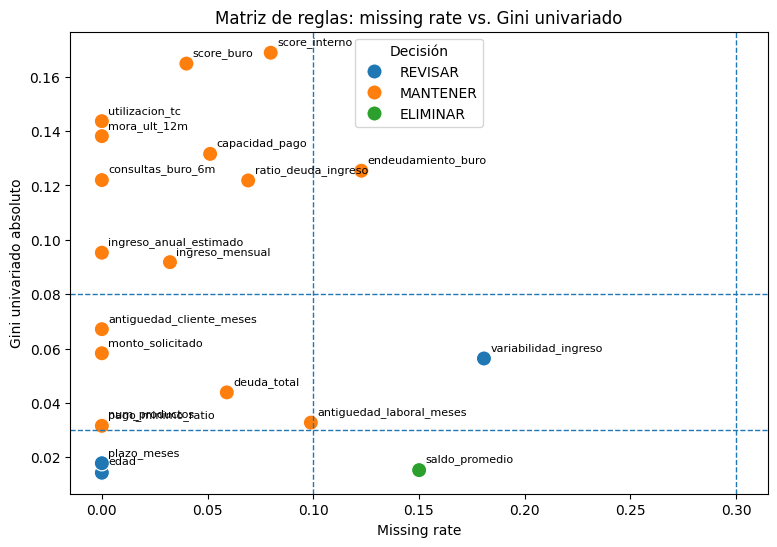

Variables seleccionadas por regla inicial:
['edad', 'ingreso_mensual', 'ingreso_anual_estimado', 'deuda_total', 'ratio_deuda_ingreso', 'endeudamiento_buro', 'utilizacion_tc', 'mora_ult_12m', 'consultas_buro_6m', 'antiguedad_laboral_meses', 'antiguedad_cliente_meses', 'score_buro', 'score_interno', 'num_productos', 'capacidad_pago', 'variabilidad_ingreso', 'pago_minimo_ratio', 'monto_solicitado', 'plazo_meses']


In [ ]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=var_diag,
    x="missing_rate",
    y="gini_univariado_abs",
    hue="decision_regla",
    s=120
)
for _, r in var_diag.iterrows():
    plt.text(r["missing_rate"] + 0.003, r["gini_univariado_abs"] + 0.003, r["variable"], fontsize=8)
plt.axvline(0.10, linestyle="--", linewidth=1)
plt.axvline(0.30, linestyle="--", linewidth=1)
plt.axhline(0.03, linestyle="--", linewidth=1)
plt.axhline(0.08, linestyle="--", linewidth=1)
plt.title("Matriz de reglas: missing rate vs. Gini univariado")
plt.xlabel("Missing rate")
plt.ylabel("Gini univariado absoluto")
plt.legend(title="Decisión")
plt.show()

selected_vars_rule = var_diag.loc[var_diag["decision_regla"].isin(["MANTENER", "REVISAR"]), "variable"].tolist()
print("Variables seleccionadas por regla inicial:")
print(selected_vars_rule)

## Correlaciones y selección apoyada en PCA

Primero se eliminan variables redundantes por alta correlación. Entre dos variables muy correlacionadas, se conserva la de mayor Gini univariado.

Luego se revisa PCA como diagnóstico de redundancia estructural. PCA no reemplaza directamente a las variables del modelo XGBoost; se usa para entender cuánta información efectiva está concentrada en pocas dimensiones.

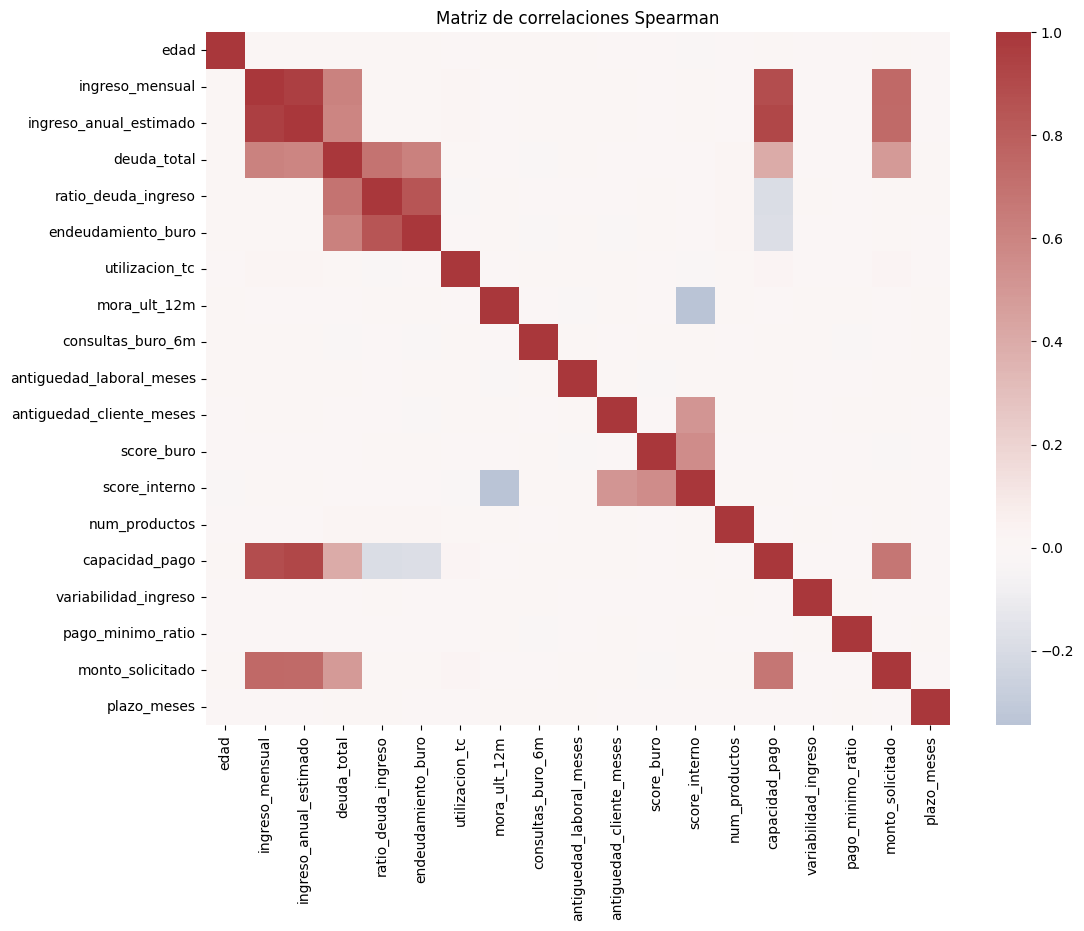

,var_1,var_2,corr_abs,keep,drop
0,ingreso_mensual,ingreso_anual_estimado,0.9553,ingreso_anual_estimado,ingreso_mensual
2,ingreso_anual_estimado,capacidad_pago,0.9113,capacidad_pago,ingreso_anual_estimado
1,ingreso_mensual,capacidad_pago,0.8833,capacidad_pago,ingreso_mensual


In [ ]:
# ============================================================
# Correlación: eliminar redundancias manteniendo mayor Gini
# ============================================================

X_train_sel = X_train_w[selected_vars_rule].copy()
X_test_sel = X_test_w[selected_vars_rule].copy()

imp_corr = SimpleImputer(strategy="median")
X_corr = pd.DataFrame(
    imp_corr.fit_transform(X_train_sel),
    columns=selected_vars_rule,
    index=X_train_sel.index
)

corr = X_corr.corr(method="spearman") #es más adecuado que pearson porque no se requiere de linealidad en la relación (porque usa rankings), así como tampoco lo requieren los GBM

plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="vlag", center=0, annot=False)
plt.title("Matriz de correlaciones Spearman")
plt.show()

gini_map = var_diag.set_index("variable")["gini_univariado_abs"].to_dict()

def drop_high_corr_features(corr_matrix, gini_map, threshold=0.85):
    cols = list(corr_matrix.columns)
    to_drop = set()
    pairs = []

    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            c1, c2 = cols[i], cols[j]
            corr_abs = abs(corr_matrix.loc[c1, c2])
            if corr_abs >= threshold:
                # Se elimina la variable con menor Gini univariado.
                drop = c1 if gini_map.get(c1, 0) < gini_map.get(c2, 0) else c2
                keep = c2 if drop == c1 else c1
                to_drop.add(drop)
                pairs.append((c1, c2, corr_abs, keep, drop))

    return sorted(to_drop), pd.DataFrame(pairs, columns=["var_1", "var_2", "corr_abs", "keep", "drop"])

corr_drop, corr_pairs = drop_high_corr_features(corr, gini_map, threshold=0.85)
corr_pairs.sort_values("corr_abs", ascending=False)

In [ ]:
selected_vars_corr = [c for c in selected_vars_rule if c not in corr_drop]
print("Variables eliminadas por alta correlación:", corr_drop)
print("Variables luego de filtro de correlación:", selected_vars_corr)

Variables eliminadas por alta correlación: ['ingreso_anual_estimado', 'ingreso_mensual']
Variables luego de filtro de correlación: ['edad', 'deuda_total', 'ratio_deuda_ingreso', 'endeudamiento_buro', 'utilizacion_tc', 'mora_ult_12m', 'consultas_buro_6m', 'antiguedad_laboral_meses', 'antiguedad_cliente_meses', 'score_buro', 'score_interno', 'num_productos', 'capacidad_pago', 'variabilidad_ingreso', 'pago_minimo_ratio', 'monto_solicitado', 'plazo_meses']


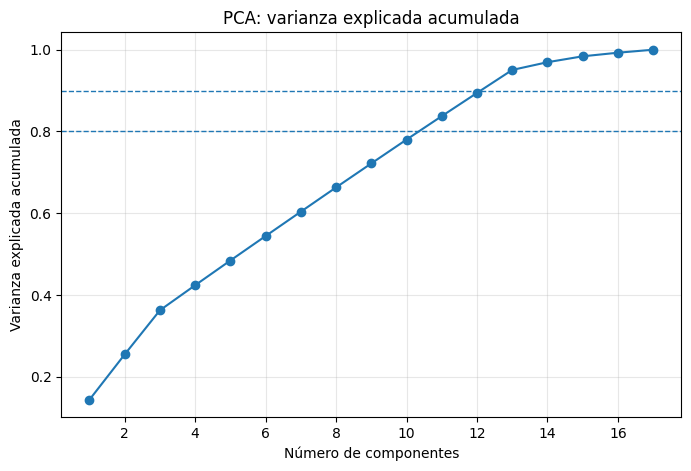

Componentes para explicar 80%: 11
Componentes para explicar 90%: 13


In [ ]:
# ============================================================
# PCA como diagnóstico
# ============================================================

pca_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(random_state=RANDOM_STATE))
])

pca_pipe.fit(X_train_w[selected_vars_corr])
pca_model = pca_pipe.named_steps["pca"]
explained = pca_model.explained_variance_ratio_
cum_explained = np.cumsum(explained)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cum_explained) + 1), cum_explained, marker="o")
plt.axhline(0.80, linestyle="--", linewidth=1)
plt.axhline(0.90, linestyle="--", linewidth=1)
plt.title("PCA: varianza explicada acumulada")
plt.xlabel("Número de componentes")
plt.ylabel("Varianza explicada acumulada")
plt.grid(alpha=0.3)
plt.show()

n80 = np.argmax(cum_explained >= 0.80) + 1
n90 = np.argmax(cum_explained >= 0.90) + 1
print(f"Componentes para explicar 80%: {n80}")
print(f"Componentes para explicar 90%: {n90}")



XGBoost y LightGBM pueden manejar relaciones no lineales e interacciones. Pero estamos imputando missings con mediana para mantener comparabilidad con SHAP, LIME y PDP.

In [ ]:
# ============================================================
# Imputación final
# ============================================================

final_vars = selected_vars_corr

final_imputer = SimpleImputer(strategy="median")
X_train_model = pd.DataFrame(
    final_imputer.fit_transform(X_train_w[final_vars]),
    columns=final_vars,
    index=X_train_w.index
)
X_test_model = pd.DataFrame(
    final_imputer.transform(X_test_w[final_vars]),
    columns=final_vars,
    index=X_test_w.index
)

X_train_model.head()

,edad,deuda_total,ratio_deuda_ingreso,endeudamiento_buro,utilizacion_tc,mora_ult_12m,consultas_buro_6m,antiguedad_laboral_meses,antiguedad_cliente_meses,score_buro,score_interno,num_productos,capacidad_pago,variabilidad_ingreso,pago_minimo_ratio,monto_solicitado,plazo_meses
1791,37.9131,"4,456.8375",1.0317,1.0882,0.1598,0.0000,2.0000,47.8445,37.1100,706.8621,799.8276,1.0000,"2,516.8677",0.2035,0.1339,"4,554.9885",24.0000
6404,36.0066,865.4948,0.2739,0.3539,0.3450,1.0000,3.0000,47.8187,28.6338,566.3893,526.6105,4.0000,"3,156.9496",0.1432,0.3953,961.8411,12.0000
2910,32.6651,"1,252.8568",0.3683,0.3190,0.6988,0.0000,3.0000,132.1713,22.5488,628.6094,595.7805,3.0000,"4,000.3086",0.0415,0.1797,"3,859.9934",12.0000
6804,45.3811,938.8459,0.3302,0.3936,0.3435,0.0000,3.0000,65.3744,9.6006,651.5965,626.2872,1.0000,"1,942.4476",0.4026,0.2025,801.9793,12.0000
3678,30.4437,589.9183,0.3683,0.1938,0.3948,1.0000,2.0000,52.9931,33.3336,626.3195,601.2340,0.0000,"3,080.3220",0.4246,0.3504,"3,164.0667",12.0000


## XGBoost

En `XGBClassifier`, los argumentos más relevantes para clase son:

- `n_estimators`: número de árboles.
- `learning_rate`: tasa de aprendizaje o shrinkage.
- `max_depth`: profundidad máxima de cada árbol.
- `min_child_weight`: peso mínimo requerido en una hoja; controla particiones débiles. Es una restricción sobre la suma de hessianos dentro de un nodo. Recuerden que el hessiano mide la sensibilidad local de la perdida, si la sensibilidad es alta, entonces aún hay espacio para aprender. Por ejemplo cuando la prob está cercana a 0% o 100%, entonces la hessiana será baja xq hay poco espacio para aprender más, ya el modelos está muy seguro de su predicción.
- `subsample`: proporción de filas usadas por árbol.
- `colsample_bytree`: proporción de variables usadas por árbol.
- `gamma`: reducción mínima de pérdida requerida para hacer una partición.
- `reg_alpha`: regularización L1.
- `reg_lambda`: regularización L2.
- `scale_pos_weight`: peso relativo de la clase positiva; útil en target desbalanceado.
- `eval_metric`: métrica de evaluación. Para scoring suele usarse `auc`.
- `tree_method`: método de construcción de árboles. `hist` suele ser rápido y estable (256 bins)
- `random_state`: reproducibilidad.

In [ ]:
# ============================================================
# XGBoost baseline con argumentos explícitos
# ============================================================

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_baseline = XGBClassifier(
    # Número de árboles
    n_estimators=400,

    # Shrinkage: menor learning_rate suele requerir más árboles
    learning_rate=0.035,

    # Complejidad de cada árbol
    max_depth=3,
    min_child_weight=20,
    gamma=0.0,

    # Muestreo por filas y columnas
    subsample=0.85,
    colsample_bytree=0.85,

    # Regularización
    reg_alpha=0.0,
    reg_lambda=3.0,

    # Desbalance de clases
    scale_pos_weight=scale_pos_weight,

    # Configuración técnica
    objective="binary:logistic",
    eval_metric="auc",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

xgb_baseline.fit(X_train_model, y_train)

pred_xgb_base = xgb_baseline.predict_proba(X_test_model)[:, 1]
auc_xgb_base = roc_auc_score(y_test, pred_xgb_base)
gini_xgb_base = 2 * auc_xgb_base - 1

print(f"AUC XGBoost baseline : {auc_xgb_base:.4f}")
print(f"Gini XGBoost baseline: {gini_xgb_base:.4f}")

AUC XGBoost baseline : 0.6698
Gini XGBoost baseline: 0.3396


## Optimización de hiperparámetros con Optuna

In [ ]:
# ============================================================
# 11. Optuna para XGBoost
# ============================================================

def objective_xgb(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 200, 900),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.12, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 6),
        "min_child_weight": trial.suggest_float("min_child_weight", 5, 80, log=True),
        "gamma": trial.suggest_float("gamma", 0.0, 8.0),
        "subsample": trial.suggest_float("subsample", 0.60, 1.00),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.60, 1.00),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.5, 20.0, log=True),
        "scale_pos_weight": scale_pos_weight,
        "objective": "binary:logistic",
        "eval_metric": "auc",
        "tree_method": "hist",
        "random_state": RANDOM_STATE,
        "n_jobs": -1
    }

    cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=RANDOM_STATE)
    aucs = []

    for tr_idx, va_idx in cv.split(X_train_model, y_train):
        X_tr, X_va = X_train_model.iloc[tr_idx], X_train_model.iloc[va_idx]
        y_tr, y_va = y_train.iloc[tr_idx], y_train.iloc[va_idx]

        model = XGBClassifier(**params)
        model.fit(X_tr, y_tr)
        pred_va = model.predict_proba(X_va)[:, 1]
        aucs.append(roc_auc_score(y_va, pred_va))

    return float(np.mean(aucs))

sampler = optuna.samplers.TPESampler(  #Tree-structured Parzen Estimator: modela distribuciones probabilísticas usando KDE (Kernel Density Estimation)
    n_startup_trials=20,
    multivariate=True,
    seed=RANDOM_STATE
)

study = optuna.create_study(
    direction="maximize",
    sampler=sampler
)

study.optimize(objective_xgb, n_trials=10,  show_progress_bar=True)


print("Mejor AUC CV:", study.best_value)
print("Mejores hiperparámetros:")
study.best_params

[I 2026-05-16 05:50:55,443] A new study created in memory with name: no-name-d85d61f5-a4ad-4852-b4fa-b61a152e8d16


  0%|          | 0/10 [00:00<?, ?it/s]

[I 2026-05-16 05:51:01,262] Trial 0 finished with value: 0.5879401325622899 and parameters: {'n_estimators': 462, 'learning_rate': 0.10616785666328349, 'max_depth': 5, 'min_child_weight': 26.292183092620917, 'gamma': 1.2481491235394921, 'subsample': 0.662397808134481, 'colsample_bytree': 0.6232334448672797, 'reg_alpha': 2.1423021757741068, 'reg_lambda': 4.591898870587326}. Best is trial 0 with value: 0.5879401325622899.
[I 2026-05-16 05:51:16,462] Trial 1 finished with value: 0.6082363230546399 and parameters: {'n_estimators': 696, 'learning_rate': 0.01052481329009022, 'max_depth': 6, 'min_child_weight': 50.272539328733295, 'gamma': 1.6987128854262092, 'subsample': 0.6727299868828402, 'colsample_bytree': 0.6733618039413735, 'reg_alpha': 0.0033205591037519565, 'reg_lambda': 3.4646653174710598}. Best is trial 1 with value: 0.6082363230546399.
[I 2026-05-16 05:51:26,743] Trial 2 finished with value: 0.5703194050893183 and parameters: {'n_estimators': 502, 'learning_rate': 0.02062001735164

{'n_estimators': 696,
 'learning_rate': 0.01052481329009022,
 'max_depth': 6,
 'min_child_weight': 50.272539328733295,
 'gamma': 1.6987128854262092,
 'subsample': 0.6727299868828402,
 'colsample_bytree': 0.6733618039413735,
 'reg_alpha': 0.0033205591037519565,
 'reg_lambda': 3.4646653174710598}

In [ ]:
best_xgb_params = {
    **study.best_params,
    "scale_pos_weight": scale_pos_weight,
    "objective": "binary:logistic",
    "eval_metric": "auc",
    "tree_method": "hist",
    "random_state": RANDOM_STATE,
    "n_jobs": -1
}

xgb_opt = XGBClassifier(**best_xgb_params)
xgb_opt.fit(X_train_model, y_train)

pred_xgb_opt = xgb_opt.predict_proba(X_test_model)[:, 1]
auc_xgb_opt = roc_auc_score(y_test, pred_xgb_opt)
gini_xgb_opt = 2 * auc_xgb_opt - 1

print(f"AUC XGBoost optimizado : {auc_xgb_opt:.4f}")
print(f"Gini XGBoost optimizado: {gini_xgb_opt:.4f}")

AUC XGBoost optimizado : 0.6644
Gini XGBoost optimizado: 0.3288


## Feature importance por Gain y eliminación de variables con gain menor a 1%

El gain mide la mejora promedio de pérdida atribuida a las particiones donde participa una variable.

Aquí se normaliza el gain para obtener participación porcentual. Luego se eliminan variables con gain menor a 1%.

In [ ]:
# ============================================================
# Gain normalizado y filtro < 1%
# ============================================================

booster = xgb_opt.get_booster()
gain_raw = booster.get_score(importance_type="gain")

gain_df = (
    pd.DataFrame({"variable": list(gain_raw.keys()), "gain": list(gain_raw.values())})
    .sort_values("gain", ascending=False)
)
gain_df["gain_pct"] = gain_df["gain"] / gain_df["gain"].sum()
gain_df

,variable,gain,gain_pct
5,mora_ult_12m,66.4369,0.0789
10,score_interno,57.1357,0.0678
6,consultas_buro_6m,54.9562,0.0652
2,ratio_deuda_ingreso,52.2548,0.0620
3,endeudamiento_buro,51.6669,0.0613
4,utilizacion_tc,51.2666,0.0609
12,capacidad_pago,51.2587,0.0608
13,variabilidad_ingreso,50.3523,0.0598
9,score_buro,49.6664,0.0590
16,plazo_meses,46.5550,0.0553


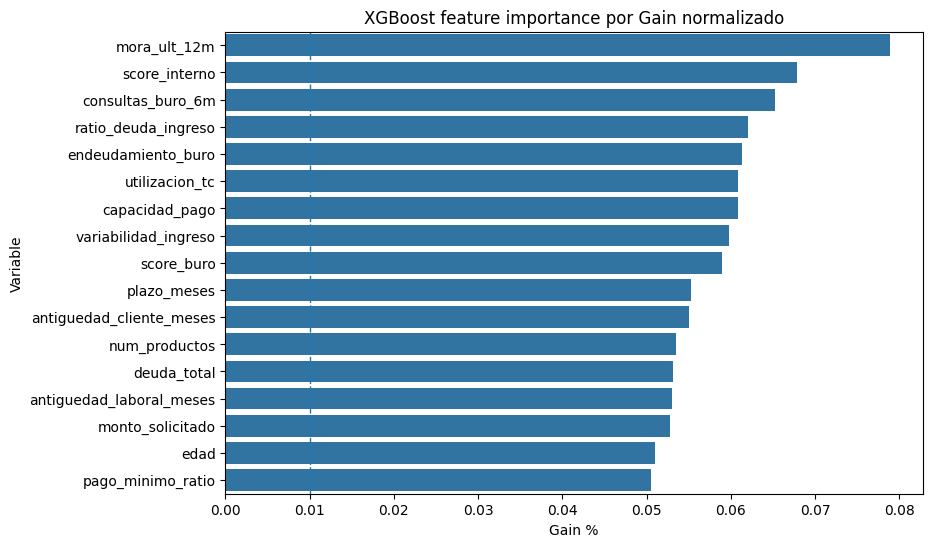

Variables a mantener: ['mora_ult_12m', 'score_interno', 'consultas_buro_6m', 'ratio_deuda_ingreso', 'endeudamiento_buro', 'utilizacion_tc', 'capacidad_pago', 'variabilidad_ingreso', 'score_buro', 'plazo_meses', 'antiguedad_cliente_meses', 'num_productos', 'deuda_total', 'antiguedad_laboral_meses', 'monto_solicitado', 'edad', 'pago_minimo_ratio']
Variables eliminadas por gain < 1%: []


In [ ]:
plt.figure(figsize=(9, 6))
sns.barplot(data=gain_df, x="gain_pct", y="variable")
plt.axvline(0.01, linestyle="--", linewidth=1)
plt.title("XGBoost feature importance por Gain normalizado")
plt.xlabel("Gain %")
plt.ylabel("Variable")
plt.show()

vars_gain_keep = gain_df.loc[gain_df["gain_pct"] >= 0.01, "variable"].tolist()
vars_gain_drop = gain_df.loc[gain_df["gain_pct"] < 0.01, "variable"].tolist()

print("Variables a mantener:", vars_gain_keep)
print("Variables eliminadas por gain < 1%:", vars_gain_drop)

In [ ]:
# Reentrenamiento final con variables filtradas por gain
X_train_final = X_train_model[vars_gain_keep].copy()
X_test_final = X_test_model[vars_gain_keep].copy()

xgb_final = XGBClassifier(**best_xgb_params)
xgb_final.fit(X_train_final, y_train)

pred_xgb_final = xgb_final.predict_proba(X_test_final)[:, 1]
auc_xgb_final = roc_auc_score(y_test, pred_xgb_final)
gini_xgb_final = 2 * auc_xgb_final - 1

print(f"AUC XGBoost final : {auc_xgb_final:.4f}")
print(f"Gini XGBoost final: {gini_xgb_final:.4f}")

AUC XGBoost final : 0.6640
Gini XGBoost final: 0.3280


## Histogramas

Se grafican distribuciones segmentadas por default para interpretar separabilidad univariada.

In [ ]:
# ============================================================
# 1Histogramas para top 3 variables por gain
# ============================================================

gain_final_raw = xgb_final.get_booster().get_score(importance_type="gain")
gain_final_df = pd.DataFrame({"variable": list(gain_final_raw.keys()), "gain": list(gain_final_raw.values())})
gain_final_df["gain_pct"] = gain_final_df["gain"] / gain_final_df["gain"].sum()
gain_final_df = gain_final_df.sort_values("gain_pct", ascending=False)

top3_vars = gain_final_df.head(3)["variable"].tolist()
top3_vars

['mora_ult_12m', 'score_interno', 'consultas_buro_6m']

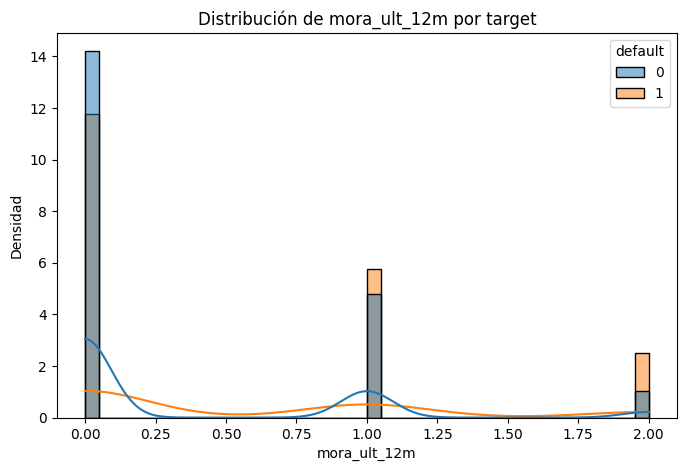

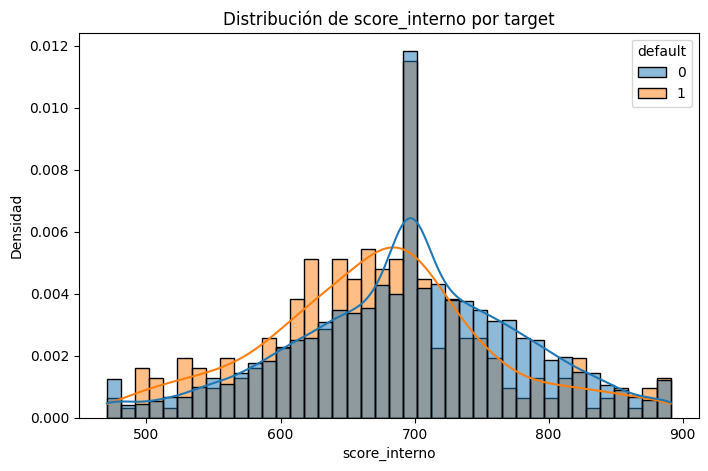

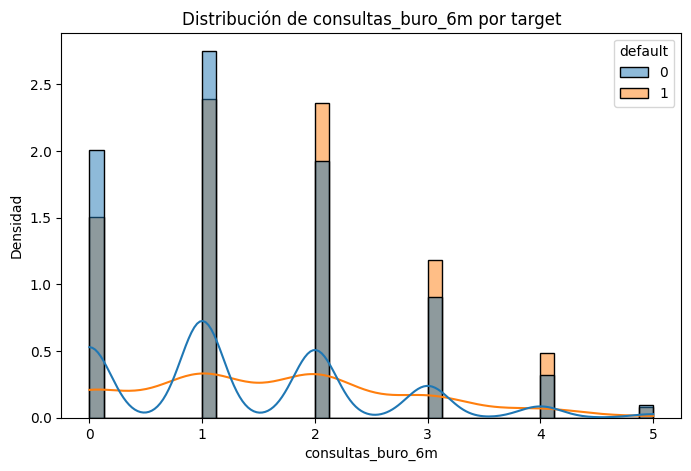

In [ ]:
  plot_df = X_train_final[top3_vars].copy()
  plot_df[target] = y_train.values

  for col in top3_vars:
      plt.figure(figsize=(8, 5))
      sns.histplot(data=plot_df, x=col, hue=target, bins=40, stat="density", common_norm=False, kde=True)
      plt.title(f"Distribución de {col} por target")
      plt.xlabel(col)
      plt.ylabel("Densidad")
      plt.show()

## 14. SHAP

SHAP permite descomponer la predicción en contribuciones por variable.

En árboles, `TreeExplainer` es eficiente y consistente con la estructura del modelo.

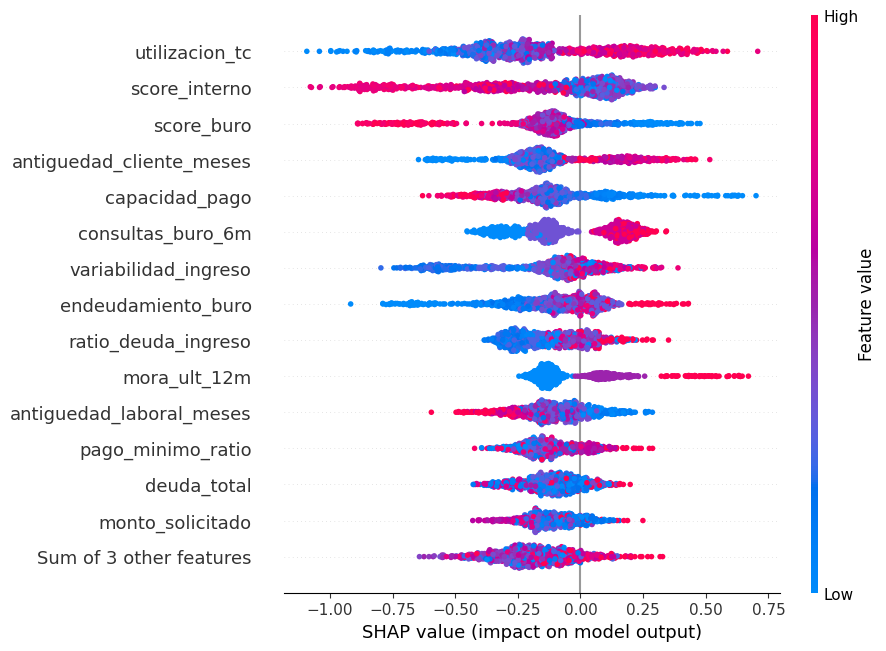

In [ ]:
# ============================================================
# SHAP
# ============================================================

# Para rapidez, se toma una muestra.
shap_sample = X_test_final.sample(min(1000, len(X_test_final)), random_state=RANDOM_STATE)

explainer = shap.TreeExplainer(xgb_final)
shap_values = explainer(shap_sample)

# Beeswarm: impacto y dirección de cada variable.
shap.plots.beeswarm(shap_values, max_display=15)

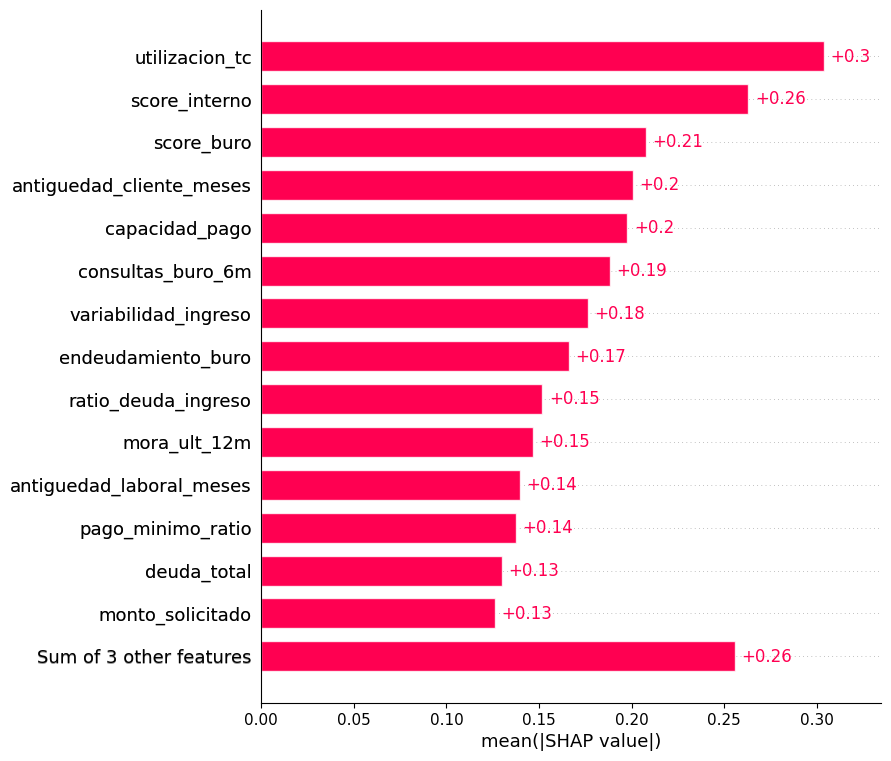

In [ ]:
# Importancia global media absoluta
shap.plots.bar(shap_values, max_display=15)

In [ ]:
explainer.model_output

'raw'

In [ ]:
raw significa que el output que está usando es log oddss.

In [ ]:
explainer.expected_value

np.float32(0.4999767)

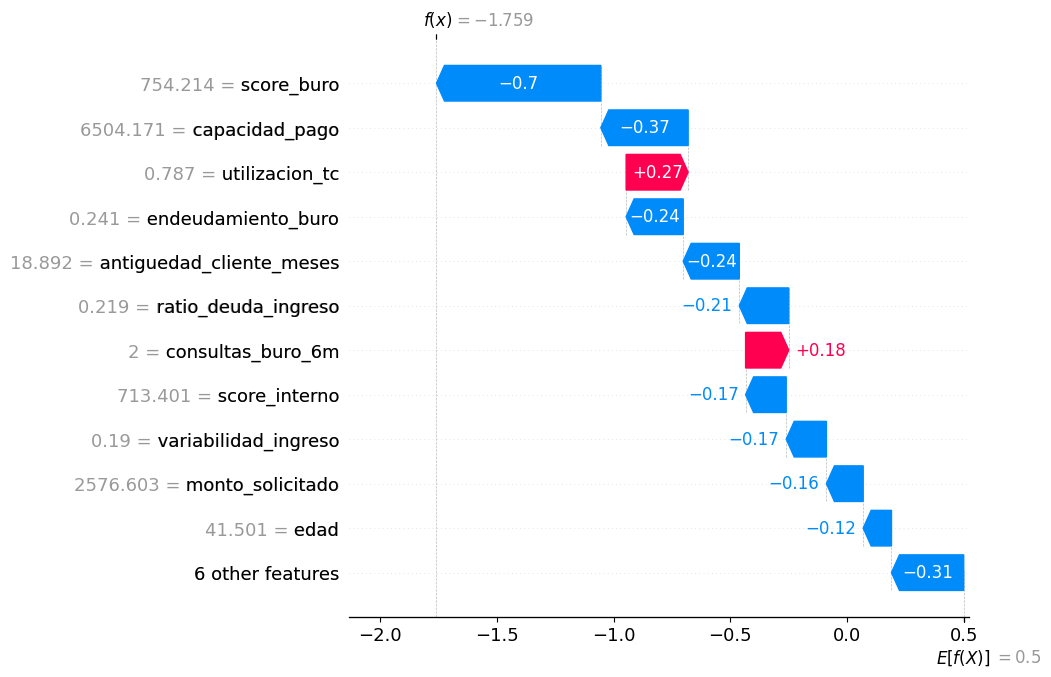

In [ ]:
# Explicación local del primer cliente
obs_idx = 0
shap.plots.waterfall(shap_values[obs_idx], max_display=12)

In [ ]:
background = X_train.sample(
    min(2000, len(X_train)),
    random_state=42
)

explainer = shap.TreeExplainer(
    xgb_final,
    data = background,
    model_output="probability"
)

shap_values = explainer(shap_sample)

 98%|===================| 984/1000 [01:13<00:01]       

In [ ]:
explainer.expected_value

np.float64(0.7078381457653607)

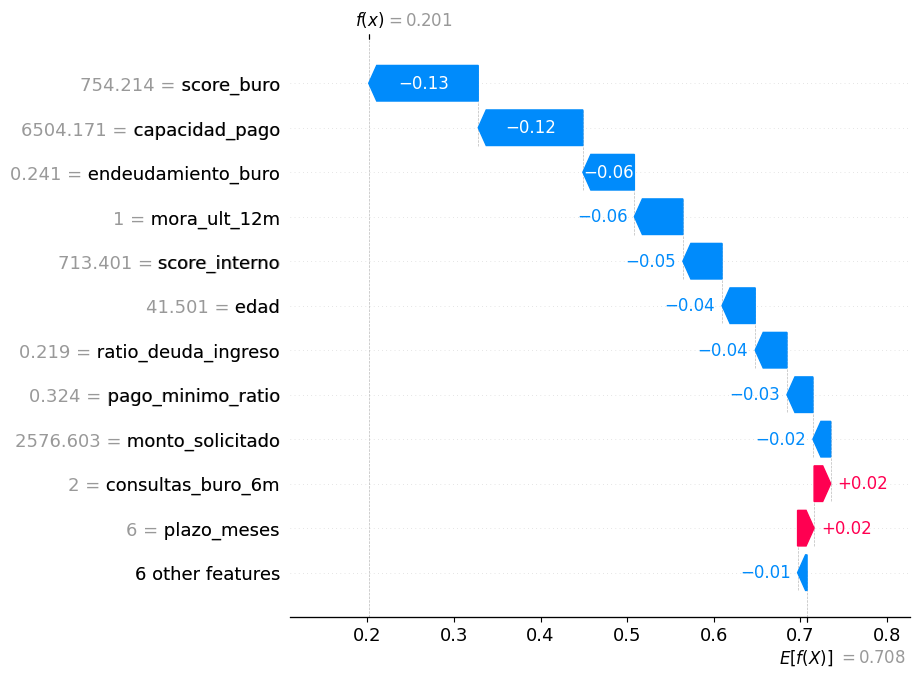

In [ ]:
# Explicación local del primer cliente
obs_idx = 0
shap.plots.waterfall(shap_values[obs_idx], max_display=12)

## Partial Dependence Plot

El PDP muestra el efecto promedio marginal de una variable sobre la predicción.

si las variables están correlacionadas, el PDP puede evaluar combinaciones poco realistas.

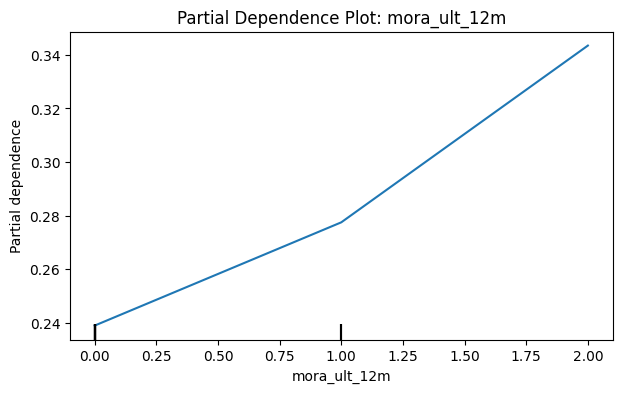

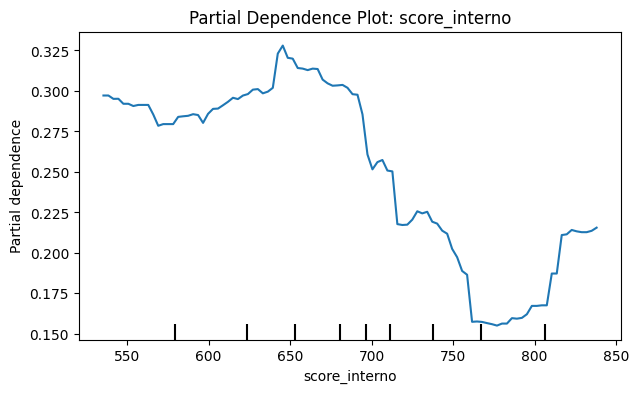

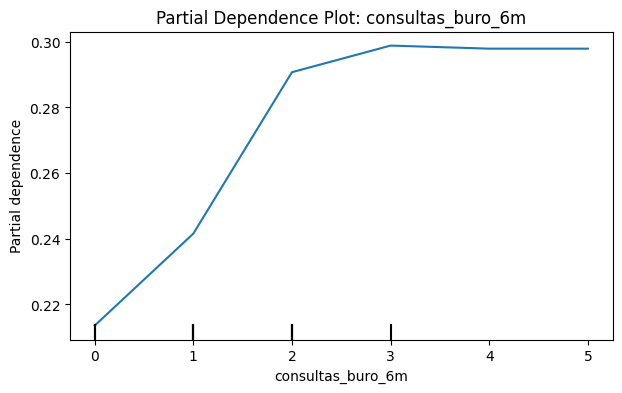

In [ ]:
# ============================================================
# Partial Dependence Plot para top 3 variables
# ============================================================

for col in top3_vars:
    fig, ax = plt.subplots(figsize=(7, 4))
    PartialDependenceDisplay.from_estimator(
        xgb_final,
        X_test_final,
        features=[col],
        kind="average",
        ax=ax
    )
    plt.title(f"Partial Dependence Plot: {col}")
    plt.show()

## LIME

LIME aproxima localmente la predicción del modelo complejo mediante un modelo interpretable alrededor de una observación específica.

In [ ]:
# ============================================================
# LIME
# ============================================================

lime_explainer = LimeTabularExplainer(
    training_data=X_train_final.values,
    feature_names=X_train_final.columns.tolist(),
    class_names=["no_default", "default"],
    mode="classification",
    discretize_continuous=True,
    random_state=RANDOM_STATE
)

obs_position = 10
obs = X_test_final.iloc[obs_position].values

lime_exp = lime_explainer.explain_instance(
    data_row=obs,
    predict_fn=xgb_final.predict_proba,
    num_features=min(10, X_test_final.shape[1])
)


print("Probabilidad predicha de default:", xgb_final.predict_proba(X_test_final.iloc[[obs_position]])[0, 1])
lime_exp.show_in_notebook(show_table=True)

Probabilidad predicha de default: 0.143652


## Comparación con LightGBM

Se entrena un LightGBM con parámetros razonables.

In [ ]:
# ============================================================
# 17. LightGBM benchmark
# ============================================================

lgbm = LGBMClassifier(
    n_estimators=600,
    learning_rate=0.035,
    max_depth=-1,
    num_leaves=31,
    min_child_samples=60,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_alpha=0.1,
    reg_lambda=3.0,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1
)

lgbm.fit(X_train_final, y_train)
pred_lgbm = lgbm.predict_proba(X_test_final)[:, 1]

auc_lgbm = roc_auc_score(y_test, pred_lgbm)
gini_lgbm = 2 * auc_lgbm - 1

summary_models = pd.DataFrame({
    "modelo": ["XGBoost final", "LightGBM"],
    "AUC": [auc_xgb_final, auc_lgbm],
    "Gini": [gini_xgb_final, gini_lgbm]
})
summary_models

,modelo,AUC,Gini
0,XGBoost final,0.6640,0.3280
1,LightGBM,0.6294,0.2587


## Curva ROC comparativa

Se grafican ambas curvas ROC en un solo diagrama.

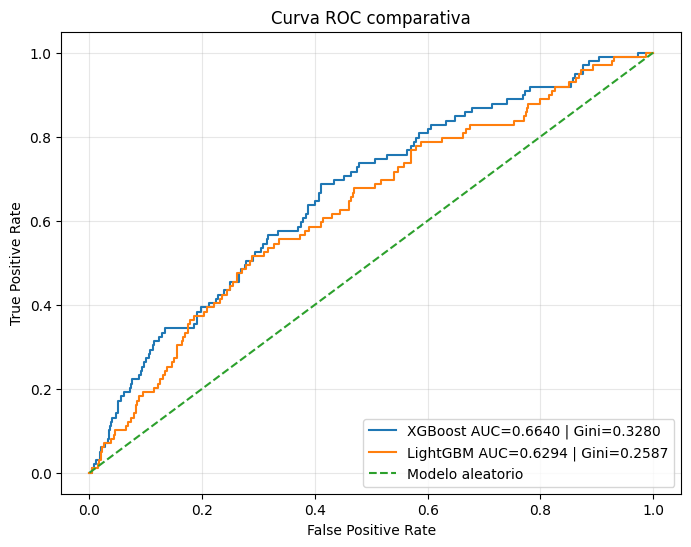

In [ ]:
# ============================================================
# ROC comparativa XGBoost vs LightGBM
# ============================================================

fpr_xgb, tpr_xgb, _ = roc_curve(y_test, pred_xgb_final)
fpr_lgbm, tpr_lgbm, _ = roc_curve(y_test, pred_lgbm)

plt.figure(figsize=(8, 6))
plt.plot(fpr_xgb, tpr_xgb, label=f"XGBoost AUC={auc_xgb_final:.4f} | Gini={gini_xgb_final:.4f}")
plt.plot(fpr_lgbm, tpr_lgbm, label=f"LightGBM AUC={auc_lgbm:.4f} | Gini={gini_lgbm:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Modelo aleatorio")
plt.title("Curva ROC comparativa")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# ============================================================
# Deciles de score como análisis adicional de scoring
# ============================================================

score_df = pd.DataFrame({
    "y_true": y_test.values,
    "pd_xgb": pred_xgb_final
})
score_df["decil_riesgo"] = pd.qcut(score_df["pd_xgb"], q=10, labels=False, duplicates="drop") + 1

deciles = (
    score_df.groupby("decil_riesgo")
    .agg(
        clientes=("y_true", "size"),
        bad_rate=("y_true", "mean"),
        pd_promedio=("pd_xgb", "mean")
    )
    .sort_index(ascending=False)
)

deciles

,clientes,bad_rate,pd_promedio
decil_riesgo,,,
10,300,0.0833,0.5778
9,300,0.0433,0.4328
8,300,0.0433,0.3551
7,300,0.0400,0.2927
6,300,0.0333,0.2422
5,300,0.0233,0.2032
4,300,0.0200,0.1658
3,300,0.0167,0.1318
2,300,0.0200,0.0975
